# Refresher RP3: Precession and Torque

**Part:** Physics refresher · **Reading time:** ~30 min · **Pass 1 overview:** [What MRI Measures](../pass1_big_picture/P1.1_What_MRI_Measures.ipynb) · **Refreshers you may want:** [ODEs for MRI](../refreshers/RM1_ODEs_for_MRI.ipynb), [Complex numbers, rotations & cross products](../refreshers/RM2_Complex_Numbers_and_Rotations.ipynb), [Magnetism from currents](../refreshers/RP1_Magnetism_from_Currents.ipynb)

Put a compass needle in a magnetic field and it swings into line with the field. Put a hydrogen nucleus in a magnetic field and it does something quite different: it **precesses**, i.e. its axis circles around the field direction at the Larmor frequency, like a tilted spinning top circling around the vertical. That one difference is the foundation of MRI. This refresher explains it with school mechanics: angular momentum, torque, the spinning top, and then the same equations for a magnetic moment, ending with the Larmor equation $\omega_0=\gamma B_0$ derived in three lines.

## Learning goals

1. Define angular momentum and torque, and state "torque = rate of change of angular momentum".
2. Explain why a torque *perpendicular* to the angular momentum makes a spinning top precess instead of falling over, and compute its precession rate.
3. Write the torque $\vec\tau=\vec\mu\times\vec B$ and energy $E=-\vec\mu\cdot\vec B$ of a magnetic moment in a field.
4. Define the **gyromagnetic ratio** $\gamma$ and derive $d\vec\mu/dt=\gamma\,\vec\mu\times\vec B$ and the Larmor frequency $\omega_0=\gamma B_0$, including the direction (clockwise).
5. Contrast a compass needle (oscillates, damps, aligns) with a nuclear spin (precesses, keeps its angle), and simulate both.

## Symbols used in this refresher

| Symbol | Meaning (plain words) | SI unit | Typical value / remark |
|---|---|---|---|
| $\vec r$ | position / lever arm from the pivot to where a force acts | m | |
| $\vec F$ | force | N | |
| $m$ | mass | kg | ⚠️ not a magnetic moment here |
| $\vec v$, $\vec p=m\vec v$ | velocity; linear momentum | m/s; kg m/s | |
| $\vec L$ | angular momentum (vector) | J s = kg m²/s | ⚠️ not the inductance of RP2 |
| $\vec\tau$ | torque ("rotational force") | N m = J | |
| $\mathcal I$ | moment of inertia (rotational "mass") | kg m² | |
| $\omega_{spin}$ | how fast a top/wheel spins about its own axis | rad/s | |
| $\Omega$ | precession angular frequency of a top | rad/s | |
| $g$ | gravitational acceleration | m/s² | 9.81 |
| $d$ | distance from the top's pivot to its centre of mass | m | |
| $\theta$ | tilt angle between an axis (or $\vec\mu$) and the vertical / field direction | rad | ⚠️ in later chapters $\theta$ = flip angle |
| $\varphi$ | azimuth (angle around the vertical / field axis) | rad | |
| $\vec\mu$ | magnetic moment (of a needle, loop or nucleus) | A m² = J/T | proton: $1.41\times10^{-26}$ J/T |
| $\vec B$, $B_0$ | magnetic field; main static field along $z$ | T | 3 T |
| $E$ | energy | J | |
| $\gamma$ | gyromagnetic ratio: magnetic moment per angular momentum | rad s⁻¹ T⁻¹ | $2.675\times10^8$ for ¹H |
| $\bar\gamma=\gamma/2\pi$ | gyromagnetic ratio in Hz/T | Hz/T | 42.58 MHz/T for ¹H |
| $\omega_0=\gamma B_0$, $f_0=\bar\gamma B_0$ | Larmor angular frequency / Larmor frequency | rad/s, Hz | 127.7 MHz at 3 T |
| $\mu_{xy}=\mu_x+i\mu_y$ | transverse part of $\vec\mu$ as a complex number | J/T | same idea as $M_{xy}$ |
| $q$, $m_p$ | charge; proton mass | C; kg | $1.602\times10^{-19}$ C; $1.673\times10^{-27}$ kg |
| $b$, $\alpha$ | damping constants in the toy models of section 7 | N m s; – | |
| $\Delta t$ | numerical time step | s | |

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath(".."))   # make ../mri_tools.py importable
import numpy as np
import matplotlib.pyplot as plt
import mri_tools as mt
mt.setup_plots()
%matplotlib inline

## 1. Angular momentum and torque

Rotational motion has its own versions of the school quantities of linear motion:

| Linear motion | Rotational motion | In words |
|---|---|---|
| position $\vec r$ | angle | where it is / which way it points |
| momentum $\vec p=m\vec v$ | **angular momentum** $\vec L=\vec r\times\vec p$ (spinning body: $\vec L=\mathcal I\,\vec\omega_{spin}$) | "quantity of rotation" |
| mass $m$ | moment of inertia $\mathcal I$ | resistance to change of (rotational) motion |
| force $\vec F$ | **torque** $\vec\tau=\vec r\times\vec F$ | "twisting effect" of a force |
| Newton: $\vec F = d\vec p/dt$ | $\vec\tau = d\vec L/dt$ | the cause changes the quantity of motion |

* **Angular momentum is a vector** along the rotation axis, direction by the right-hand rule: curl the fingers of your right hand with the rotation, the thumb points along $\vec L$. A wheel spinning counter-clockwise as seen from above has $\vec L$ pointing up. Its size for a spinning body is $L=\mathcal I\omega_{spin}$ [J s].
* **Torque** $\vec\tau = \vec r\times\vec F$ [N m]: a force $\vec F$ applied at lever arm $\vec r$ from the pivot. Its size is $rF\sin\alpha$ ($\alpha$ = angle between $\vec r$ and $\vec F$): pushing a door far from the hinge and perpendicular to it is most effective. Its direction (right-hand rule again) is the axis about which the force tries to turn the body.
* The rotational Newton law

$$\frac{d\vec L}{dt} = \vec\tau$$

In words: a torque changes the angular momentum *in the direction of the torque*; without torque, $\vec L$ stays constant (which is why a spinning bicycle wheel or a gyroscope keeps its orientation).
Where: $\vec L$ = angular momentum [J s], $\vec\tau$ = torque [N m], $t$ = time [s].

> **🔁 Refresher:** The cross product $\vec a\times\vec b$ is perpendicular to both $\vec a$ and $\vec b$, has size $ab\sin\alpha$, and its direction follows the right-hand rule. [RM2](../refreshers/RM2_Complex_Numbers_and_Rotations.ipynb).

## 2. The spinning top: why it precesses instead of falling

Hold a bicycle wheel by one end of its axle and let go: if it is **not** spinning, it simply falls. If it **is** spinning fast, it does something surprising: it stays (almost) horizontal and its axle slowly swings around the vertical. This motion is **precession**. A tilted spinning top does the same.

Why? Gravity $m\vec g$ pulls down at the centre of mass, at lever arm $\vec r = d\,\hat{\vec L}$ along the axis from the pivot. The torque $\vec\tau = \vec r\times m\vec g$ is **horizontal** and **perpendicular** to the axis (and to $\vec L$).

* *Not spinning:* $\vec L = 0$ at the start. The torque builds up angular momentum along $\vec\tau$, i.e. rotation about a horizontal axis: the top falls over.
* *Spinning fast:* $\vec L$ is large and points along the axis. In a short time $dt$ the torque adds $d\vec L = \vec\tau\,dt$, which is **perpendicular to $\vec L$**. Adding a small perpendicular vector to a big vector **rotates** it without changing its length. So the axis is pushed *sideways*, not down: it moves around the vertical, forever (until friction slows the spin).

This is the same geometry as uniform circular motion: a force always perpendicular to the velocity changes its direction, not its speed.

<details><summary><b>📐 Derivation of the precession rate (optional)</b></summary>

Let the axis be tilted by $\theta$ from the vertical. The horizontal part of $\vec L$ has length $L\sin\theta$. The torque has size $\tau = m g d\sin\theta$ and is horizontal and perpendicular to that horizontal part. In time $dt$ the horizontal part of $\vec L$ turns by an angle $d\varphi = \tau\,dt/(L\sin\theta)$. Hence

$$\Omega = \frac{d\varphi}{dt} = \frac{m g d\sin\theta}{L\sin\theta} = \frac{m g d}{L}.$$

Vectorially: $\vec\tau = d\hat{\vec L}\times(-mg\hat z) = \frac{mgd}{L}\,\hat z\times\vec L$, so $\frac{d\vec L}{dt} = \vec\Omega\times\vec L$ with $\vec\Omega = \frac{mgd}{L}\hat z$: rotation of $\vec L$ about the vertical with angular velocity $\Omega$.

(This "gyroscopic approximation" assumes the spin is fast, $\Omega\ll\omega_{spin}$, so that $\vec L$ points along the axis. A real top also wobbles slightly — **nutation**. For a nucleus there is no such complication, as we will see.)

</details>

The result

$$\Omega = \frac{m\,g\,d}{L}$$

In words: the top precesses at a rate set by the torque divided by the angular momentum — **independent of the tilt angle**, and slower the faster it spins.
Where: $\Omega$ = precession angular frequency [rad/s], $m$ = mass [kg], $g = 9.81$ m/s², $d$ = pivot–centre-of-mass distance [m], $L = \mathcal I\omega_{spin}$ = spin angular momentum [J s].

### Demo: integrating the top's equation of motion

We integrate $d\vec L/dt = \vec\tau(\vec L)$ numerically with a standard 4th-order Runge–Kutta (RK4) step (a short inline version is used here because *how* the step works is part of the lesson; see [RM1](../refreshers/RM1_ODEs_for_MRI.ipynb) for numerical stepping). Toy gyroscope: a 100 g disc of radius 3 cm spinning at 50 revolutions per second, centre of mass 4 cm from the pivot.

L = 0.0141 J s, predicted precession Omega = 2.78 rad/s  (period 2.26 s)


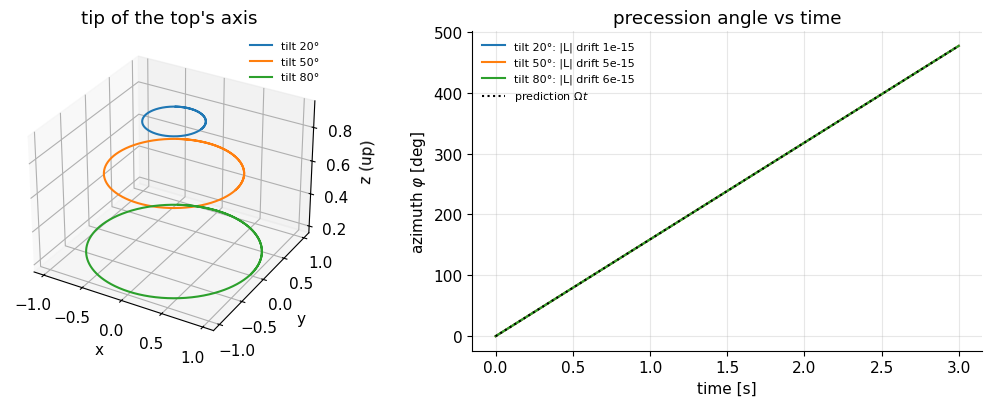

In [2]:
def rk4_step(f, X, dt):
    """One 4th-order Runge-Kutta step for dX/dt = f(X)."""
    k1 = f(X); k2 = f(X + dt / 2 * k1); k3 = f(X + dt / 2 * k2); k4 = f(X + dt * k3)
    return X + dt / 6 * (k1 + 2 * k2 + 2 * k3 + k4)

def integrate(f, X0, dt, n_steps, step=rk4_step):
    X = np.empty((n_steps + 1, len(X0))); X[0] = X0
    for n in range(n_steps):
        X[n + 1] = step(f, X[n], dt)
    return X

m_top, r_disc, d_top, g = 0.1, 0.03, 0.04, 9.81
I_mom = 0.5 * m_top * r_disc**2                        # moment of inertia of a disc [kg m^2]
w_spin = 2 * np.pi * 50                                # 50 rev/s [rad/s]
L_mag = I_mom * w_spin                                 # |L| [J s]
Omega = m_top * g * d_top / L_mag
print(f"L = {L_mag:.4f} J s, predicted precession Omega = {Omega:.2f} rad/s  (period {2 * np.pi / Omega:.2f} s)")

def top_rhs(L):
    """dL/dt = torque of gravity, lever arm d along the axis (gyroscopic approximation)."""
    axis = L / np.linalg.norm(L)
    return np.cross(d_top * axis, np.array([0, 0, -m_top * g]))

fig = plt.figure(figsize=(11, 4.2))
ax3 = fig.add_subplot(1, 2, 1, projection="3d"); ax2 = fig.add_subplot(1, 2, 2)
t = np.arange(0, 3.0, 1e-3)
for tilt in [20, 50, 80]:                              # tilt from vertical [deg]
    th = np.deg2rad(tilt)
    L0 = L_mag * np.array([np.sin(th), 0, np.cos(th)])
    Ls = integrate(top_rhs, L0, 1e-3, len(t) - 1)
    ax3.plot(*(Ls / L_mag).T, label=f"tilt {tilt}°")
    azim = np.unwrap(np.arctan2(Ls[:, 1], Ls[:, 0]))
    ax2.plot(t, np.rad2deg(azim), label=f"tilt {tilt}°: |L| drift {abs(np.linalg.norm(Ls[-1]) / L_mag - 1):.0e}")
ax3.set_xlabel("x"); ax3.set_ylabel("y"); ax3.set_zlabel("z (up)"); ax3.set_title("tip of the top's axis")
ax2.plot(t, np.rad2deg(Omega * t), "k:", label=r"prediction $\Omega t$")
ax2.set_xlabel("time [s]"); ax2.set_ylabel(r"azimuth $\varphi$ [deg]"); ax2.set_title("precession angle vs time")
ax2.legend(fontsize=8); ax3.legend(fontsize=8); plt.tight_layout(); plt.show()

Left: the tip of the axis moves on a horizontal circle at constant height — the top neither falls nor rises. Right: the azimuth grows linearly at the predicted rate $\Omega = mgd/L$ for **all three tilts** (the lines coincide), and the length of $\vec L$ is conserved. Seen from above, this top precesses counter-clockwise ($\vec\Omega$ points up). Remember that — the nucleus will turn the other way.

## 3. A magnetic moment in a magnetic field

A small current loop, a bar magnet, a compass needle and a nucleus all behave, seen from outside, like a **magnetic dipole** with **magnetic moment** $\vec\mu$ [A m² = J/T]. For a flat current loop $\mu = I\cdot A$ (current × area), pointing along the loop's axis by the right-hand rule ([RP1](../refreshers/RP1_Magnetism_from_Currents.ipynb)). In a magnetic field $\vec B$ the dipole feels a **torque** and has a potential **energy**:

$$\vec\tau = \vec\mu\times\vec B,\qquad E = -\vec\mu\cdot\vec B = -\mu B\cos\theta .$$

In words: the field tries to twist the moment into line with itself (torque $\mu B\sin\theta$, zero when aligned or anti-aligned), and the energy is lowest when $\vec\mu$ points along $\vec B$ and highest when it points against it.
Where: $\vec\mu$ = magnetic moment [J/T], $\vec B$ = field [T], $\theta$ = angle between them, $\vec\tau$ in N m (J/T × T = J = N m ✓), $E$ in J.

(In a *uniform* field there is no net force, only torque. A net force — the projectile effect — needs a field that changes with position, see [MRI Safety](../pass2_deep_dive/B6_MRI_Safety.ipynb).)

## 4. Compass needle versus nucleus

Both feel the same torque $\vec\mu\times\vec B$. The difference is **what the torque acts on**:

* A **compass needle** has a magnetic moment but (before it starts to move) no angular momentum to speak of. The torque gives it angular momentum *about the axis of the torque*: it rotates toward the field, overshoots, swings back — a pendulum. Friction with the air and the pivot removes energy and it settles along $\vec B$: it **aligns**.
* A **nucleus** such as the proton has an intrinsic angular momentum (**spin**) that can never be zero or slowed down, and its magnetic moment is locked to it:

$$\vec\mu = \gamma\,\vec L .$$

In words: the nuclear magnetic moment is always parallel to its spin angular momentum, scaled by a fixed constant for each type of nucleus.
Where: $\gamma$ = **gyromagnetic ratio** [rad s⁻¹ T⁻¹] ("gyro" = spinning, "magnetic" ratio = magnetic moment per angular momentum; check the units: (J/T)/(J s) = 1/(T s), and "rad" is added because it will turn out to be an angular frequency per tesla). For ¹H, $\gamma = 2.675\times10^8$ rad s⁻¹ T⁻¹, i.e. $\bar\gamma = \gamma/2\pi = 42.58$ MHz/T.

So the nucleus is a spinning top, and the magnetic torque, like gravity on the top, is perpendicular to $\vec L$. It therefore **precesses**.

<details><summary><b>📐 Where does γ come from? A classical estimate (optional)</b></summary>

A charge $q$ of mass $m$ circling at speed $v$ on a circle of radius $a$ is a current $I = q/(\text{period}) = qv/(2\pi a)$ around an area $\pi a^2$, so $\mu = I\pi a^2 = qva/2$. Its angular momentum is $L = mva$. Hence $\mu/L = q/(2m)$, the "classical" gyromagnetic ratio. For a proton this gives $q/(2m_p)= 4.79\times10^7$ rad s⁻¹ T⁻¹. The measured value is $2.675\times10^8$, i.e. 5.59 times larger (the proton's "g-factor" $g_p = 5.586$). The difference reflects the proton's internal quark structure; even the neutron, with zero net charge, has a magnetic moment. So $\gamma$ is best treated as a measured constant per nucleus — see the table below and [RP4](../refreshers/RP4_Spin_and_Thermal_Statistics.ipynb).

</details>

In [3]:
q, m_p = 1.602176634e-19, 1.67262192e-27
print(f"classical q/(2 m_p) = {q / (2 * m_p):.3e} rad/s/T ; measured gamma(1H) = {mt.GAMMA:.4e} -> ratio {mt.GAMMA / (q / (2 * m_p)):.3f}\n")
print(f"{'nucleus':8s} {'gamma-bar [MHz/T]':>18s} {'f0 at 3 T [MHz]':>16s}")
for nuc, gb in mt.GAMMA_BAR_NUCLEI.items():
    print(f"{nuc:8s} {gb / 1e6:18.3f} {mt.larmor_frequency(3.0, gb) / 1e6:16.2f}")
print(f"{'electron':8s} {-28024.95:18.3f} {-28024.95 * 3:16.0f}   (|gamma_e| is ~658x the proton's: EPR/ESR)")

classical q/(2 m_p) = 4.789e+07 rad/s/T ; measured gamma(1H) = 2.6752e+08 -> ratio 5.586

nucleus   gamma-bar [MHz/T]  f0 at 3 T [MHz]
1H                   42.577           127.73
2H                    6.536            19.61
13C                  10.708            32.12
19F                  40.078           120.23
23Na                 11.262            33.79
31P                  17.235            51.70
129Xe               -11.777           -35.33
electron         -28024.950           -84075   (|gamma_e| is ~658x the proton's: EPR/ESR)


Each nucleus has its own $\gamma$, hence its own resonance frequency at a given field: a 3 T scanner tuned to 127.7 MHz "hears" only protons; imaging ¹³C, ²³Na or ³¹P needs extra RF hardware at other frequencies. A negative $\gamma$ (e.g. ¹²⁹Xe, and the electron) means $\vec\mu$ is antiparallel to $\vec L$ and the precession runs the other way.

## 5. Deriving the Larmor precession

Start from the rotational Newton law with the magnetic torque, $d\vec L/dt = \vec\mu\times\vec B$, and multiply both sides by $\gamma$ (using $\vec\mu = \gamma\vec L$):

$$\frac{d\vec\mu}{dt} = \gamma\,\vec\mu\times\vec B .$$

In words: the moment changes in a direction perpendicular to both itself and the field, at a rate proportional to $\gamma B$. This is the **Bloch equation without relaxation**, for a single moment.
Where: $\vec\mu$ [J/T], $\gamma$ [rad s⁻¹ T⁻¹], $\vec B$ [T].

Now take a static field along $z$, $\vec B = [0,0,B_0]^T$. Writing out the cross product $\vec\mu\times\vec B = [\mu_yB_0,\,-\mu_xB_0,\,0]^T$:

$$\frac{d\mu_x}{dt} = \gamma B_0\,\mu_y,\qquad \frac{d\mu_y}{dt} = -\gamma B_0\,\mu_x,\qquad \frac{d\mu_z}{dt}=0 .$$

In words: $\mu_z$ never changes; the transverse components feed into each other, which is the signature of a rotation. To solve the coupled pair, combine them into one complex number $\mu_{xy} = \mu_x + i\mu_y$:

$$\frac{d\mu_{xy}}{dt} = \gamma B_0(\mu_y - i\mu_x) = -i\gamma B_0(\mu_x + i\mu_y) = -i\omega_0\,\mu_{xy},\qquad \omega_0 \equiv \gamma B_0 .$$

This is the simplest linear ODE, $dy/dt = ky$, with solution $y(t)=y(0)e^{kt}$ ([RM1](../refreshers/RM1_ODEs_for_MRI.ipynb)), here with $k=-i\omega_0$:

$$\mu_{xy}(t) = \mu_{xy}(0)\,e^{-i\omega_0 t},\qquad \mu_z(t) = \mu_z(0),\qquad \omega_0 = \gamma B_0,\quad f_0 = \bar\gamma B_0 .$$

In words: the transverse part keeps its length and rotates with angular frequency $\omega_0=\gamma B_0$ (the **Larmor frequency**), the longitudinal part stays fixed — the tip of $\vec\mu$ circles around $\vec B$ on a cone of constant opening angle.
Where: $\mu_{xy}$ = transverse moment as complex number [J/T], $\omega_0$ [rad/s], $f_0$ [Hz]; for ¹H at 3 T, $f_0 = 42.58\times3 = 127.7$ MHz.

**Direction.** $e^{-i\omega_0 t}$ means the angle of $\mu_{xy}$ *decreases* with time: seen from the tip of $\vec B$ (looking down from $+z$), the moment precesses **clockwise**, i.e. it is a **left-handed** rotation about $\vec B$. In vector form $d\vec\mu/dt = \vec\Omega\times\vec\mu$ with $\vec\Omega = -\gamma\vec B$, compared with $\vec\Omega=+\frac{mgd}{L}\hat z$ for the top. (For negative $\gamma$ the precession is counter-clockwise.)

> **⚠️ Common confusion:** Some textbooks draw proton precession counter-clockwise, or write $e^{+i\omega t}$. With $\vec\mu=\gamma\vec L$, $\gamma>0$ and $\vec\tau=\vec\mu\times\vec B$, the physics gives clockwise. In imaging, sign conventions only flip images or frequency axes, but mixing conventions is a common source of bugs. This series and `mri_tools` always use clockwise: $M_{xy}(t)=M_{xy}(0)e^{-i\omega t}$.

> **🧭 Intuition — why the frequency does not depend on the tilt:** both the torque ($\mu B\sin\theta$) and the radius of the circle the tip has to travel ($\propto \mu\sin\theta$) scale with $\sin\theta$, so the angular speed is the same at every tilt — exactly as for the top. This is why *all* protons in the same field precess at the same frequency, which makes MRI possible.

### Demo: integrate $d\vec\mu/dt=\gamma\vec\mu\times\vec B$ and compare with `mt.bloch_rotate`

We take a proton moment (normalized to length 1) tilted 60° from $z$ in a 3 T field, and integrate 3 Larmor periods (one period $1/f_0 = 7.83$ ns) with (a) the simple forward-Euler step $\vec\mu_{n+1} = \vec\mu_n + \Delta t\, \gamma\vec\mu_n\times\vec B$, (b) RK4, and (c) the exact rotation used throughout this series, `mt.bloch_rotate`.

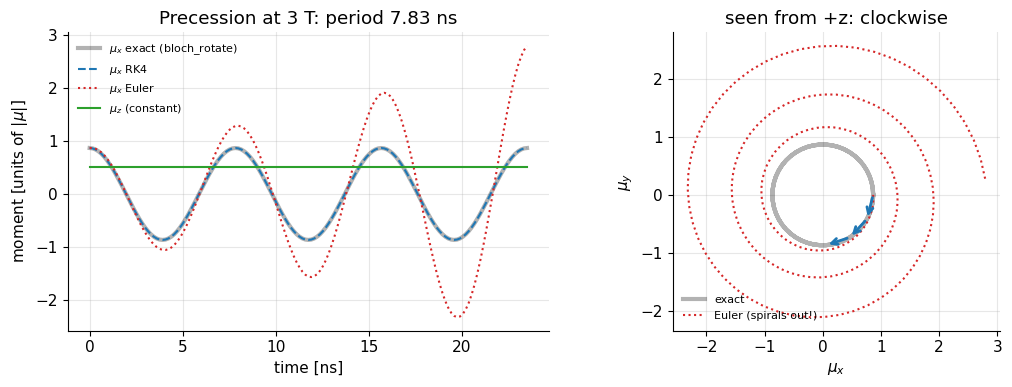

measured frequency from the phase slope: 127.731 MHz (gamma_bar*B0 = 127.731 MHz; negative slope = clockwise)
max |RK4 - exact| = 3.4e-05;  Euler: |mu| grew to 2.85


In [4]:
B0 = 3.0
B = np.array([0.0, 0.0, B0])
f0 = mt.larmor_frequency(B0); T0 = 1 / f0
mu0 = np.array([np.sin(np.deg2rad(60)), 0.0, np.cos(np.deg2rad(60))])   # tilted 60 deg, |mu| = 1
dt = T0 / 50                                  # 50 steps per Larmor period
n = 150                                       # 3 periods
t = np.arange(n + 1) * dt

spin_rhs = lambda mu: mt.GAMMA * np.cross(mu, B)
euler_step = lambda f, X, h: X + h * f(X)
mu_euler = integrate(spin_rhs, mu0, dt, n, step=euler_step)
mu_rk4 = integrate(spin_rhs, mu0, dt, n)
mu_exact = mt.bloch_rotate(np.tile(mu0, (n + 1, 1)), t, B)      # rotation by gamma*|B|*t, clockwise

fig, axs = plt.subplots(1, 2, figsize=(11, 4))
axs[0].plot(t * 1e9, mu_exact[:, 0], "k-", lw=3, alpha=0.3, label=r"$\mu_x$ exact (bloch_rotate)")
axs[0].plot(t * 1e9, mu_rk4[:, 0], "C0--", label=r"$\mu_x$ RK4")
axs[0].plot(t * 1e9, mu_euler[:, 0], "C3:", label=r"$\mu_x$ Euler")
axs[0].plot(t * 1e9, mu_rk4[:, 2], "C2-", label=r"$\mu_z$ (constant)")
axs[0].set_xlabel("time [ns]"); axs[0].set_ylabel(r"moment [units of $|\mu|$]"); axs[0].legend(fontsize=8)
axs[0].set_title(f"Precession at 3 T: period {T0 * 1e9:.2f} ns")
axs[1].plot(mu_exact[:, 0], mu_exact[:, 1], "k-", lw=3, alpha=0.3, label="exact")
axs[1].plot(mu_euler[:, 0], mu_euler[:, 1], "C3:", label="Euler (spirals out!)")
for k in [0, 4, 8]:                                            # arrows showing the sense of rotation
    axs[1].annotate("", xy=mu_exact[k + 4, :2], xytext=mu_exact[k, :2], arrowprops=dict(arrowstyle="->", color="C0", lw=2))
axs[1].set_aspect("equal"); axs[1].set_xlabel(r"$\mu_x$"); axs[1].set_ylabel(r"$\mu_y$")
axs[1].set_title("seen from +z: clockwise"); axs[1].legend(fontsize=8, loc="lower left")
plt.tight_layout(); plt.show()

phase = np.unwrap(np.angle(mu_rk4[:, 0] + 1j * mu_rk4[:, 1]))
print(f"measured frequency from the phase slope: {-np.polyfit(t, phase, 1)[0] / (2 * np.pi) / 1e6:.3f} MHz "
      f"(gamma_bar*B0 = {f0 / 1e6:.3f} MHz; negative slope = clockwise)")
print(f"max |RK4 - exact| = {np.abs(mu_rk4 - mu_exact).max():.1e};  Euler: |mu| grew to {np.linalg.norm(mu_euler[-1]):.2f}")

RK4 and the exact rotation agree to ~10⁻⁵ and give exactly $\bar\gamma B_0 = 127.7$ MHz, rotating clockwise; $\mu_z$ stays constant. Forward Euler, by contrast, makes the moment grow on every step (each step moves along the tangent, slightly off the circle) — a classic reason why Bloch simulators, including `mt.bloch_rotate`, apply an exact rotation per time step instead of naive Euler stepping (see [Bloch Equation](../pass2_deep_dive/A2_Bloch_Equation.ipynb)).

## 6. Precession conserves energy — so why do spins ever align?

The magnetic energy $E=-\vec\mu\cdot\vec B=-\mu B_0\cos\theta$ depends only on the tilt $\theta$. Precession keeps $\theta$ constant, so it **conserves energy**: $dE/dt = -\vec B\cdot d\vec\mu/dt = -\gamma\vec B\cdot(\vec\mu\times\vec B)=0$ (a vector triple product with a repeated vector is zero). An isolated spin in a static field would precess at the same angle forever.

To move toward alignment (lower energy) the spin must **give energy away** to its surroundings; to tip away from alignment it must **receive** energy. In MRI:

* **Receiving energy = excitation:** a weak RF field $B_1$ that rotates *in step with the precession* (at the Larmor frequency, i.e. on **resonance**) exerts a torque that keeps pushing the moment the same way, tipping it further from $z$ — like pushing a swing at the right rhythm ([RF Pulses](../pass2_deep_dive/E1_RF_Pulses.ipynb)). Seen in a frame rotating at $\omega_0$ (the **rotating frame**), $B_0$ seems to vanish and the moment simply precesses about $B_1$ ([Bloch Equation](../pass2_deep_dive/A2_Bloch_Equation.ipynb)).
* **Giving energy away = relaxation:** thermal interactions with the molecular environment slowly return the magnetization to equilibrium ($T_1$, and loss of phase coherence $T_2$; [Bloch Equation](../pass2_deep_dive/A2_Bloch_Equation.ipynb)). This takes milliseconds to seconds — about 10⁸ precession periods at 3 T — so on the time scale of precession the spins behave as if they were isolated.

| ![RF excitation, lab frame](../images/RF_hard_lab_frame_on-resonance.gif) | ![RF excitation, rotating frame](../images/RF_hard_rotating_frame_on-resonance.gif) |
| :-: | :-: |
| Excitation seen in the lab frame: fast precession about $B_0$ plus a slow tip | Same, in the rotating frame: only the slow tip about $B_1$ |

*(Animations from the original book.)*

## 7. The CompassMR picture: needle vs spin, simulated

The free [CompassMR](https://www.drcmr.dk/CompassMR/) simulator (L. G. Hanson, DRCMR) lets you push a compass needle and a "spin" in a field. Here is a Python equivalent with three toy models in a field along $z$, all with a natural frequency of 1 Hz so that we can watch them (real protons at 3 T are 10⁸ times faster):

1. **Compass needle** (no intrinsic spin): a damped pendulum, $\mathcal I\ddot\theta = -\mu B\sin\theta - b\dot\theta$ (moment of inertia × angular acceleration = magnetic torque − friction), moving in the $x$–$z$ plane.
2. **Nuclear spin**: $d\vec\mu/dt=\gamma\vec\mu\times\vec B$.
3. **Spin with weak damping**: $d\vec\mu/dt=\gamma\vec\mu\times\vec B - \alpha\gamma\,\hat{\vec\mu}\times(\vec\mu\times\vec B)$; the extra term pulls $\vec\mu$ toward $\vec B$ without changing its length (a "Landau–Lifshitz" damping, a toy stand-in for energy loss).

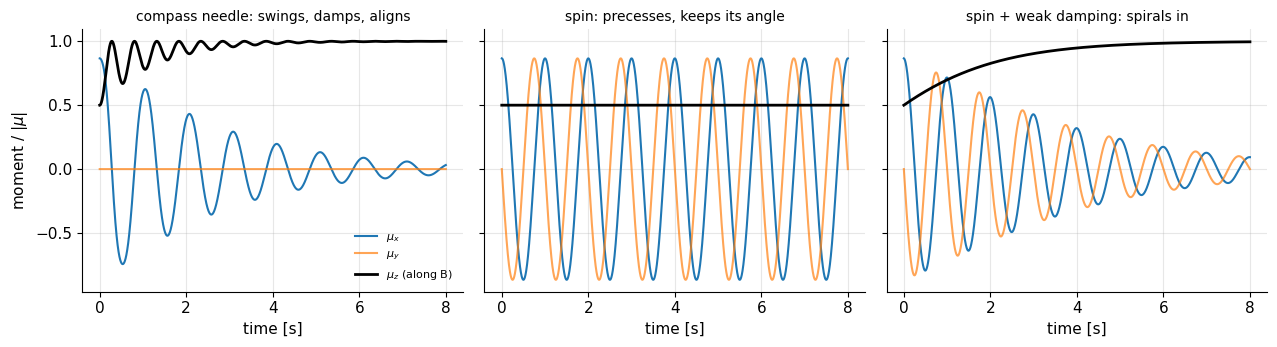

In [5]:
wc = 2 * np.pi * 1.0                 # natural angular frequency of all three toys [rad/s] (1 Hz)
dt, n = 2e-3, 4000                   # 8 s
t = np.arange(n + 1) * dt
th0 = np.deg2rad(60)                 # all start tilted 60 deg from the field

# 1) compass needle: state X = [theta, dtheta/dt];  theta'' = -wc^2 sin(theta) - (b/I) theta'
b_over_I = 0.8                       # friction [1/s]
needle = integrate(lambda X: np.array([X[1], -wc**2 * np.sin(X[0]) - b_over_I * X[1]]), np.array([th0, 0.0]), dt, n)
needle_mu = np.stack([np.sin(needle[:, 0]), 0 * needle[:, 0], np.cos(needle[:, 0])], axis=-1)

# 2) spin, and 3) damped spin, with gamma*B = wc (toy values)
Bt = np.array([0, 0, 1.0]); gam = wc
mu_init = np.array([np.sin(th0), 0, np.cos(th0)])
spin = integrate(lambda mu: gam * np.cross(mu, Bt), mu_init, dt, n)
alpha = 0.05
damped = integrate(lambda mu: gam * np.cross(mu, Bt) - alpha * gam * np.cross(mu / np.linalg.norm(mu), np.cross(mu, Bt)),
                   mu_init, dt, n)

fig, axs = plt.subplots(1, 3, figsize=(13, 3.6), sharey=True)
for ax, data, title in zip(axs, [needle_mu, spin, damped],
                           ["compass needle: swings, damps, aligns", "spin: precesses, keeps its angle",
                            "spin + weak damping: spirals in"]):
    ax.plot(t, data[:, 0], label=r"$\mu_x$"); ax.plot(t, data[:, 1], label=r"$\mu_y$", alpha=0.7)
    ax.plot(t, data[:, 2], "k", lw=2, label=r"$\mu_z$ (along B)")
    ax.set_title(title, fontsize=10); ax.set_xlabel("time [s]")
axs[0].set_ylabel(r"moment / $|\mu|$"); axs[0].legend(fontsize=8)
plt.tight_layout(); plt.show()

* **Needle:** $\mu_y=0$ (it swings in a plane, back and forth *through* the field direction); $\mu_z\to1$ within a few seconds — it aligns.
* **Spin:** $\mu_x$ and $\mu_y$ oscillate 90° out of phase (rotation about $z$, clockwise), with constant amplitude; $\mu_z$ is constant. It never aligns.
* **Damped spin:** it precesses *and* slowly spirals up into alignment; $\mu_z\to1$. This looks like relaxation, but beware:

> **⚠️ Common confusion:** Real $T_1$/$T_2$ relaxation is **not** a friction acting on each nucleus. The magnetization $\vec M$ is the average over ~10¹⁹ spins per mm³; relaxation comes from random fluctuating fields from molecular motion that make the *ensemble* drift back to thermal equilibrium ([RP4](../refreshers/RP4_Spin_and_Thermal_Statistics.ipynb), [Bloch Equation](../pass2_deep_dive/A2_Bloch_Equation.ipynb)). Also, $T_2$ decay *shrinks* $|M_{xy}|$ faster than $M_z$ recovers, which a length-preserving damping like ours cannot do. The toy only illustrates that *losing energy* is what turns precession into alignment.

**Try it in CompassMR:** (1) default compass mode, press "Push": the needle oscillates, damps and aligns; (2) tick the coil option and push again: the oscillating needle induces a signal in the coil ([RP2](../refreshers/RP2_Induction_and_RF.ipynb)); (3) switch to "Spin" mode and push: it now precesses in 3D around the field.

<details><summary><b>📐 Aside: does the compass needle have no spin at all? (optional)</b></summary>

Its magnetism *does* come from electron spins, so a magnetized needle carries intrinsic angular momentum $L = \mu/|\gamma_e|$. For a needle with $\mu\approx0.01$ A m², this is $0.01/1.76\times10^{11}\approx6\times10^{-14}$ J s — utterly negligible compared with the mechanical angular momentum it gets when it swings ($\mathcal I\dot\theta\sim10^{-9}$–$10^{-7}$ J s). That tiny intrinsic angular momentum is real, though: it was measured in the Einstein–de Haas experiment (1915), where magnetizing an iron rod makes it rotate. For a nucleus there is *only* the intrinsic part, so the gyroscopic behaviour is exact — no nutation.

</details>

## Where this shows up in MRI

| Concept from this refresher | Where it is used |
|---|---|
| Spin, magnetic moment, $\gamma$, Larmor frequency $f_0=\bar\gamma B_0$, precession, resonance | [Spin Physics](../pass2_deep_dive/A1_Spin_Physics.ipynb) |
| $d\vec M/dt=\gamma\vec M\times\vec B$, clockwise convention, rotating frame, numerical rotation steps | [Bloch Equation](../pass2_deep_dive/A2_Bloch_Equation.ipynb) |
| Field-dependent frequency (chemical shift, off-resonance) | [In Vivo Spin Physics](../pass2_deep_dive/A3_In_Vivo_Spin_Physics.ipynb) |
| Excitation by a resonant rotating $B_1$ | [RF Pulses](../pass2_deep_dive/E1_RF_Pulses.ipynb) |
| Frequency ∝ field → spatial encoding with gradients | [Spatial Encoding](../pass2_deep_dive/F1_Spatial_Encoding.ipynb) |

## Key takeaways

* Torque changes angular momentum: $d\vec L/dt=\vec\tau$, with $\vec\tau=\vec r\times\vec F$.
* A torque perpendicular to $\vec L$ rotates $\vec L$ instead of lengthening it: a spinning top **precesses** at $\Omega = mgd/L$, independent of its tilt.
* A magnetic moment in a field feels $\vec\tau=\vec\mu\times\vec B$ and has energy $E=-\vec\mu\cdot\vec B$.
* For a nucleus, $\vec\mu=\gamma\vec L$ (gyromagnetic ratio $\gamma$), so $d\vec\mu/dt=\gamma\,\vec\mu\times\vec B$ → precession at $\omega_0=\gamma B_0$, $f_0=\bar\gamma B_0$ (127.7 MHz at 3 T for ¹H), independent of the tilt.
* For $\gamma>0$ the precession is **clockwise** seen from $+z$ (left-handed): $\mu_{xy}(t)=\mu_{xy}(0)e^{-i\omega_0t}$.
* A compass needle aligns because it swings and loses energy to friction; a spin precesses because its angular momentum is intrinsic. Precession conserves energy; alignment requires energy exchange (RF excitation, relaxation).

## Check your understanding

1. A bicycle wheel spinning about a horizontal axle is held at one end. Why doesn't it fall, and what happens if it spins twice as fast?

<details><summary>Answer</summary>

Gravity's torque is horizontal and perpendicular to the wheel's angular momentum, so it changes the *direction* of $\vec L$ (sideways) rather than tipping it down: the axle precesses around the vertical. With twice the spin, $L$ doubles and the precession rate $\Omega=mgd/L$ halves.

</details>

2. Show that $\vec\tau=\vec\mu\times\vec B$ has the units of a torque.

<details><summary>Answer</summary>

$[\mu][B]$ = (J/T)·T = J = N m, the unit of torque. (Equivalently A m² · N/(A m) = N m.)

</details>

3. What is the Larmor frequency of ¹H at 1.5 T and of ²³Na at 3 T? How long is one ¹H precession period at 7 T?

<details><summary>Answer</summary>

¹H at 1.5 T: 42.58 × 1.5 = 63.9 MHz. ²³Na at 3 T: 11.26 × 3 = 33.8 MHz. ¹H at 7 T: $f_0=298$ MHz, period $1/f_0\approx3.4$ ns.

</details>

4. Starting from $d\vec\mu/dt=\gamma\vec\mu\times\vec B$ with $\vec B=B_0\hat z$, show that $|\vec\mu|$ and $\mu_z$ are constant.

<details><summary>Answer</summary>

$\frac{d}{dt}|\vec\mu|^2 = 2\vec\mu\cdot\frac{d\vec\mu}{dt} = 2\gamma\,\vec\mu\cdot(\vec\mu\times\vec B) = 0$ because $\vec\mu\times\vec B\perp\vec\mu$. And $d\mu_z/dt$ is the $z$-component of $\gamma\vec\mu\times B_0\hat z$, which is $\gamma B_0(\mu_x\cdot0-\mu_y\cdot0)=0$ — the cross product with $\hat z$ has no $z$-component.

</details>

5. Why does a single isolated proton not "fall" into alignment with $B_0$, and what makes the net magnetization of a sample align anyway?

<details><summary>Answer</summary>

Precession conserves the magnetic energy $-\vec\mu\cdot\vec B$, so without an energy sink the angle stays fixed. In a sample, thermal interactions with the surroundings (the "lattice") exchange energy with the spins; the ensemble drifts toward the thermal-equilibrium distribution that slightly favours the low-energy orientation, giving a net $M_0$ along $B_0$ (time constant $T_1$). See [RP4](../refreshers/RP4_Spin_and_Thermal_Statistics.ipynb).

</details>

6. A ¹²⁹Xe nucleus has $\bar\gamma=-11.78$ MHz/T. In which sense does it precess about $B_0$?

<details><summary>Answer</summary>

With $\gamma<0$, $\omega_0=\gamma B_0<0$: $\mu_{xy}(t)=\mu_{xy}(0)e^{-i\omega_0 t}=\mu_{xy}(0)e^{+i|\omega_0|t}$, i.e. **counter-clockwise** (right-handed) seen from $+z$, at $|f_0| = 11.78$ MHz/T × $B_0$.

</details>

---
*New refresher written for this adaptation; it expands the "Precession" and CompassMR parts of P. Larson, "Principles of MRI" (MIT License), chapter "Spin Physics" (original animations reused, Python equivalent of the CompassMR compass/spin demonstration added).*

*References:* D. Halliday, R. Resnick & J. Walker, *Fundamentals of Physics* (Wiley), chapters on rotation and angular momentum · L. G. Hanson, "Is quantum mechanics necessary for understanding magnetic resonance?", *Concepts Magn. Reson. A* 32, 329–340 (2008) · L. G. Hanson, CompassMR simulator, https://www.drcmr.dk/CompassMR/ · M. H. Levitt, *Spin Dynamics: Basics of Nuclear Magnetic Resonance* (Wiley) · E. M. Haacke et al., *Magnetic Resonance Imaging: Physical Principles and Sequence Design* (Wiley).